In [1]:
import pysam
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import argparse
import os
from collections import Counter

def parse_bam(wk_dir, title=""):
    alignment_file = os.path.join(wk_dir, "aligned_contigs.bam")
    assert os.path.exists(alignment_file), "Working dir must contain aligned_contigs.bam!"
    # out_dir = os.path.join(wk_dir, "plots")
    # if not os.path.exists(out_dir):
    #     os.makedirs(out_dir, exist_ok=True)

    # Set default title if not provided
    if not title:
        title = f"Insertion map for {alignment_file}"

    print(f"Step 2: Set alignment file to '{alignment_file}'")

    # --- Step 3: Data Processing (Extracting Insertion Sites and Genome Length) ---
    print("\nStep 3: Processing alignment file...")

    # Counter for tracking filtered reads.
    filter_counts = Counter({
        "unmapped": 0,
        "low_mapq": 0,
        "secondary": 0,
        "supplementary": 0,
    })
    insertion_sites, reference_names = [], []
    # total_genome_length = 0

    # Open the SAM/BAM file once to process reads and get header info.
    with pysam.AlignmentFile(alignment_file, "r") as samfile:
        # Get total genome length from the SAM/BAM header.
        if samfile.header.lengths:
            total_genome_lengths = dict(zip(samfile.header.references, samfile.header.lengths))
            print(f"Total genome lengths from header:")
            for genome, length in total_genome_lengths.items():
                print(f"\t{genome}: {length:,} bp")

        # Process all aligned reads in the file.
        for read in samfile.fetch(until_eof=True):
            # Check which filtering condition the read meets.
            if read.is_unmapped:
                filter_counts["unmapped"] += 1
                continue
            # MAPQ=0 often means a read maps to multiple locations.
            if read.mapping_quality == 0:
                filter_counts["low_mapq"] += 1
                continue
            # Secondary/supplementary alignments are alternative mappings for the same read.
            if read.is_secondary:
                filter_counts["secondary"] += 1
                continue
            if read.is_supplementary:
                filter_counts["supplementary"] += 1
                continue

            # For reads that pass the filters, get the 5' end position.
            pos = read.reference_end - 1 if read.is_reverse else read.reference_start
            insertion_sites.append(pos)
            reference_names.append(read.reference_name)

    # Report the filtering statistics.
    total_reads = sum(filter_counts.values()) + len(insertion_sites)
    print(f"Total reads processed: {total_reads:,}")
    for reason, count in filter_counts.items():
        print(f"  - {reason:14s}: {count:,} reads filtered out")
    print(f"  - Kept for analysis: {len(insertion_sites):,} reads")


    # --- Step 4: Data Aggregation and Formatting ---
    print("\nStep 4: Aggregating data...")

    positions_df = pd.DataFrame([insertion_sites, reference_names], index=['position', 'reference']).T

    # Convert to 1-based indexing
    positions_df["position"] += 1

    # Convert the results into a DataFrame for plotting.
    counts_df = pd.DataFrame(positions_df.groupby("reference")["position"].value_counts()).reset_index()

    # Add a column for plotting in Megabases (Mb).
    counts_df['position_mb'] = counts_df['position'] / 1_000_000
    # NOTE: The log10_count column is calculated but not used in the plot, so it's removed for clarity.
    print("  - Data aggregation complete.")
    return counts_df, positions_df, total_genome_lengths, title

wk_dir = "../data/CJ5Z9Y_v0"

sample_1 = parse_bam(f"{wk_dir}/CJ5Z9Y_1")
sample_2 = parse_bam(f"{wk_dir}/sample_2_full")
sample_3 = parse_bam(f"{wk_dir}/CJ5Z9Y_3")

Step 2: Set alignment file to '../data/CJ5Z9Y_v0/CJ5Z9Y_1/aligned_contigs.bam'

Step 3: Processing alignment file...
Total genome lengths from header:
	pSES0099: 9,503 bp
	pSES0114: 142,357 bp
	gSES0128_insilico_wgs: 4,633,946 bp
Total reads processed: 4,199
  - unmapped      : 196 reads filtered out
  - low_mapq      : 0 reads filtered out
  - secondary     : 0 reads filtered out
  - supplementary : 0 reads filtered out
  - Kept for analysis: 4,003 reads

Step 4: Aggregating data...
  - Data aggregation complete.
Step 2: Set alignment file to '../data/CJ5Z9Y_v0/sample_2_full/aligned_contigs.bam'

Step 3: Processing alignment file...
Total genome lengths from header:
	pSES0099: 9,503 bp
	pSES0114: 142,357 bp
	gSES0128_insilico_wgs: 4,633,946 bp
Total reads processed: 3,012
  - unmapped      : 88 reads filtered out
  - low_mapq      : 0 reads filtered out
  - secondary     : 0 reads filtered out
  - supplementary : 0 reads filtered out
  - Kept for analysis: 2,924 reads

Step 4: Aggrega

In [33]:
sns.set_style("whitegrid")


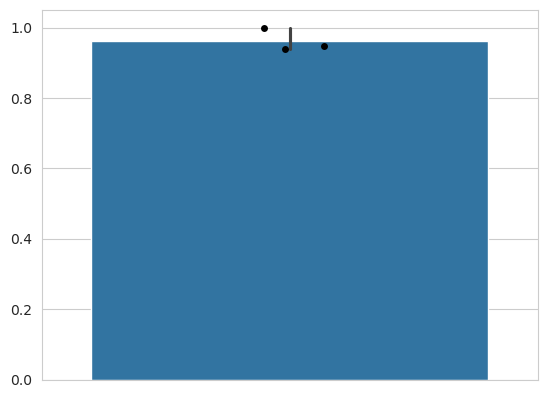

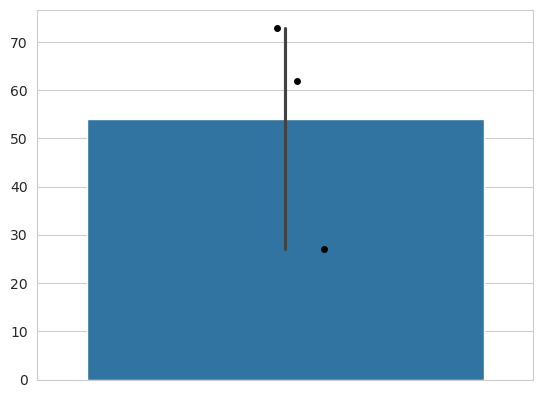

In [34]:
counts_df_1, positions_df_1, total_genome_lengths_1, _ = sample_1
counts_df_2, positions_df_2, total_genome_lengths_2, _ = sample_2
counts_df_3, positions_df_3, total_genome_lengths_3, _ = sample_3

target_genome = "gSES0128_insilico_wgs"
target_pos = 3843421
leniency = 10



def calc_on_target(counts_df):
    lower = counts_df["position"] >= target_pos - leniency
    upper = counts_df["position"] <= target_pos + leniency
    genome_mask = counts_df["reference"] == target_genome
    genome_hits = counts_df[genome_mask].copy()
    genome_hits["On Target"] = False
    genome_hits.loc[(lower & upper), "On Target"] = True
    n_on_target = genome_hits.loc[genome_hits["On Target"], "count"].sum()
    n_off_target = genome_hits.loc[~genome_hits["On Target"], "count"].sum()
    pct_on_target = n_on_target / (n_on_target + n_off_target)
    return pct_on_target, n_on_target

s1p, s1n = calc_on_target(counts_df_1)
s2p, s2n = calc_on_target(counts_df_2)
s3p, s3n = calc_on_target(counts_df_3)

sns.barplot({"": [s1p, s2p, s3p]})
sns.stripplot([s1p, s2p, s3p], c='k')
plt.show()
sns.barplot({"": [s1n, s2n, s3n]})
sns.stripplot([s1n, s2n, s3n], c='k')
plt.show()